# Tarea 2, Pregunta 3: Identificación no supervisada de estados meteorológicos y detección de anomalías

En esta pregunta abordamos la identificación de estados meteorológicos y la detección de eventos climáticos extremos en la zona de Santiago, trabajando en un escenario puramente no supervisado: no contamos con etiquetas ni con confirmaciones visuales de la tormenta eléctrica en la zona. El desafío consiste en descubrir la **firma matemática de la tormenta** a partir de la sola estructura de los datos.

Para eso usamos un dataset meteorológico de la API de **Open-Meteo** (Historical Weather API), con observaciones horarias de Santiago entre el 2024-10-15 y el 2026-10-15. El dataset reúne 17.544 registros y 12 variables atmosféricas (temperatura, humedad, presión, viento, precipitación, etc.). Como el ejercicio es no supervisado, descartamos cualquier variable objetivo o etiqueta.

El objetivo se desglosa en cinco tareas:

1. Reducir la dimensionalidad con una técnica espacial, justificando estadísticamente la información retenida.
2. Aplicar dos enfoques de agrupamiento: uno por partición (con centroide más cercano) y otro por densidad, aislando las zonas dispersas.
3. Evaluar la calidad geométrica de los agrupamientos con métricas de validación interna.
4. Analizar cómo la normalización y la métrica de distancia determinan la forma de los clústeres y la sensibilidad a la detección de anomalías.
5. Analizar si las anomalías detectadas ocurren de forma contigua en el tiempo, evidenciando el ciclo de vida de la tormenta (formación, clímax y disipación).


## 1. Librerías y configuración

Fijamos una semilla al inicio para que todos los resultados del notebook sean reproducibles.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semilla para reproducibilidad
SEMILLA = 42
np.random.seed(SEMILLA)

# Configuración para mostrar resultados de forma ordenada
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 2. Carga y exploración de datos

El archivo descargado desde Open-Meteo no comienza directamente con la cabecera de los datos, ya que incluye 3 líneas de metadatos (coordenadas, elevación y huso horario) antes de la fila de encabezado real. Por eso lo leemos con `skiprows=3`, para quedarnos directamente con la tabla de observaciones.

In [ ]:
RUTA = "Datasets/open-meteo-33.36S70.56W906m.csv"

df = pd.read_csv(RUTA, skiprows=3)
df.head()

Revisamos la forma del dataset, el nombre de cada columna y sus tipos.

In [4]:
print("Dimensiones:", df.shape)
print()
print("Columnas:")
print(df.columns.tolist())

Dimensiones: (17544, 13)

Columnas:
['time', 'temperature_2m (°C)', 'relative_humidity_2m (%)', 'dew_point_2m (°C)', 'apparent_temperature (°C)', 'precipitation (mm)', 'rain (mm)', 'surface_pressure (hPa)', 'wind_speed_10m (km/h)', 'wind_direction_10m (°)', 'cloud_cover (%)', 'pressure_msl (hPa)', 'soil_temperature_0_to_7cm (°C)']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 13 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   time                            17544 non-null  str    
 1   temperature_2m (°C)             17544 non-null  float64
 2   relative_humidity_2m (%)        17544 non-null  int64  
 3   dew_point_2m (°C)               17544 non-null  float64
 4   apparent_temperature (°C)       17544 non-null  float64
 5   precipitation (mm)              17544 non-null  float64
 6   rain (mm)                       17544 non-null  float64
 7   surface_pressure (hPa)          17544 non-null  float64
 8   wind_speed_10m (km/h)           17544 non-null  float64
 9   wind_direction_10m (°)          17544 non-null  int64  
 10  cloud_cover (%)                 17544 non-null  int64  
 11  pressure_msl (hPa)              17544 non-null  float64
 12  soil_temperature_0_to_7cm (°C)  17544 non-n

El dataset no tiene valores nulos y las 12 variables meteorológicas ya vienen en formato numérico, por lo que no hace falta imputar ni codificar nada.

### Rango temporal

In [6]:
df["time"] = pd.to_datetime(df["time"])

print("Primera observación:", df["time"].min())
print("Última observación :", df["time"].max())
print("Total de observaciones horarias:", len(df))
print("Duración aproximada   :", df["time"].max() - df["time"].min())

Primera observación: 2024-10-15 00:00:00
Última observación : 2026-10-15 23:00:00
Total de observaciones horarias: 17544
Duración aproximada   : 730 days 23:00:00


La serie es horaria y continua: 17.544 registros en un intervalo de 730 días, con un único intervalo de muestreo de 1 hora.

In [7]:
d = df["time"].diff().dropna()
print("Intervalos de muestreo:")
print(d.value_counts().head())
print("Timestamps duplicados:", df["time"].duplicated().sum())
print("Gaps mayores a 1 hora:", (d > pd.Timedelta(hours=1)).sum())

Intervalos de muestreo:
time
0 days 01:00:00    17543
Name: count, dtype: int64
Timestamps duplicados: 0
Gaps mayores a 1 hora: 0


### Estadísticas descriptivas

In [8]:
df.describe().T.round(3)

,count,mean,min,25%,50%,75%,max,std
time,17544,2025-10-15 11:30:00,2024-10-15 00:00:00,2025-04-15 17:45:00,2025-10-15 11:30:00,2026-04-16 05:15:00,2026-10-15 23:00:00,NaN
temperature_2m (°C),17544.0,15.603426,-2.1,11.3,15.2,19.5,32.9,5.956979
relative_humidity_2m (%),17544.0,54.061161,7.0,38.0,53.0,70.0,100.0,20.512144
dew_point_2m (°C),17544.0,5.136753,-26.1,2.8,6.2,8.8,15.8,5.361335
apparent_temperature (°C),17544.0,14.21824,-6.0,9.6,14.0,18.5,33.3,6.45218
precipitation (mm),17544.0,0.069978,0.0,0.0,0.0,0.0,8.7,0.416144
rain (mm),17544.0,0.06629,0.0,0.0,0.0,0.0,8.7,0.393157
surface_pressure (hPa),17544.0,913.60786,898.9,912.1,913.7,915.1,924.6,2.453374
wind_speed_10m (km/h),17544.0,4.571643,0.0,1.2,3.2,7.2,27.1,4.071424
wind_direction_10m (°),17544.0,174.267613,3.0,117.0,189.0,223.0,360.0,63.438452


De la tabla descriptiva se observa la heterogeneidad de escalas entre variables, la presión se mueve alrededor de 1016 hPa con una desviación de solo 3.3, mientras que la humedad relativa tiene desviación 20.5 y la temperatura 6.0. La precipitación y la lluvia están sesgadas a cero (ya que la mediana es cercana a 0).

### Distribución de las variables

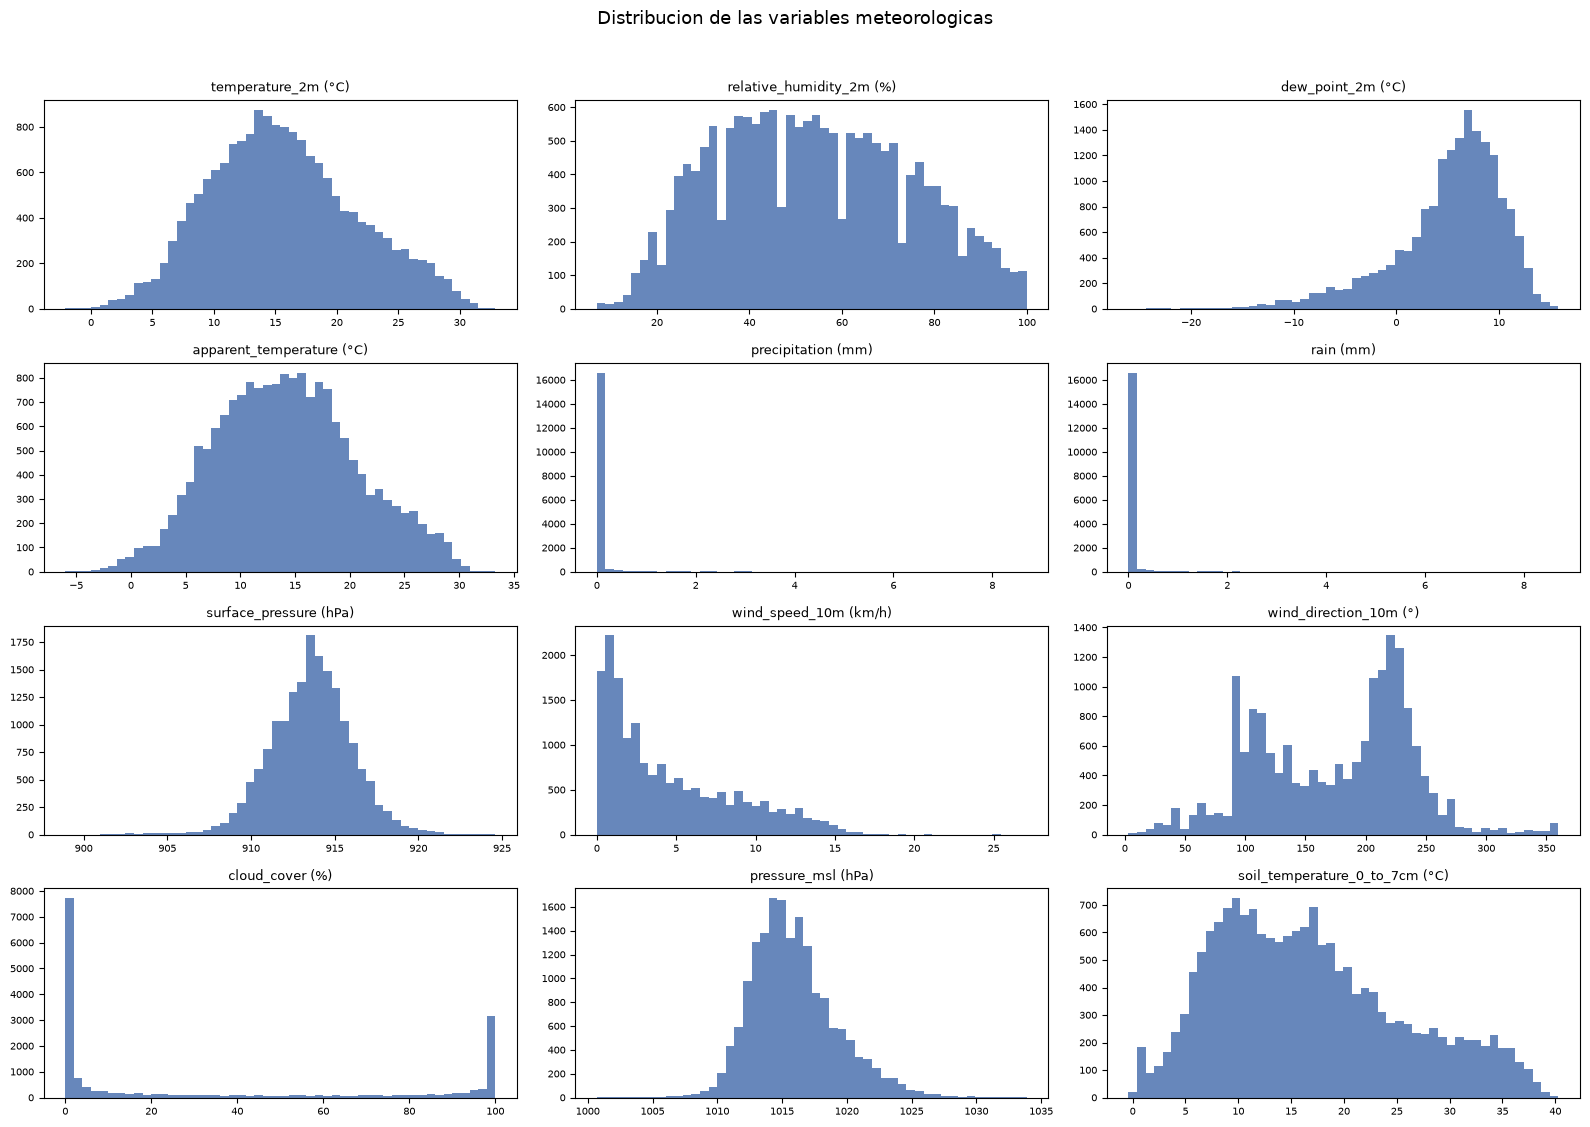

In [9]:
num = df.drop(columns=["time"])

fig, axes = plt.subplots(4, 3, figsize=(16, 11))
axes = axes.ravel()
for ax, c in zip(axes, num.columns):
    ax.hist(num[c], bins=50, color="#4C72B0", alpha=0.85)
    ax.set_title(c, fontsize=9)
    ax.tick_params(labelsize=7)
plt.suptitle("Distribucion de las variables meteorologicas", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

Los histogramas muestran tres patrones: la precipitación y la lluvia son *zero-inflated*, donde la mayoría de horas no llueve, la humedad y la cobertura de nubes son bimodales, así teniendo días despejados frente a días nublados, y las temperaturas se concentran alrededor de un valor central, con una forma de campana simétrica. La dirección del viento es angular (0° a 360°), por lo que hay que tratarla antes de usarla.

### Correlación entre variables

Dado que las variables atmosféricas suelen estar fuertemente correlacionadas, calculamos la matriz de correlación.

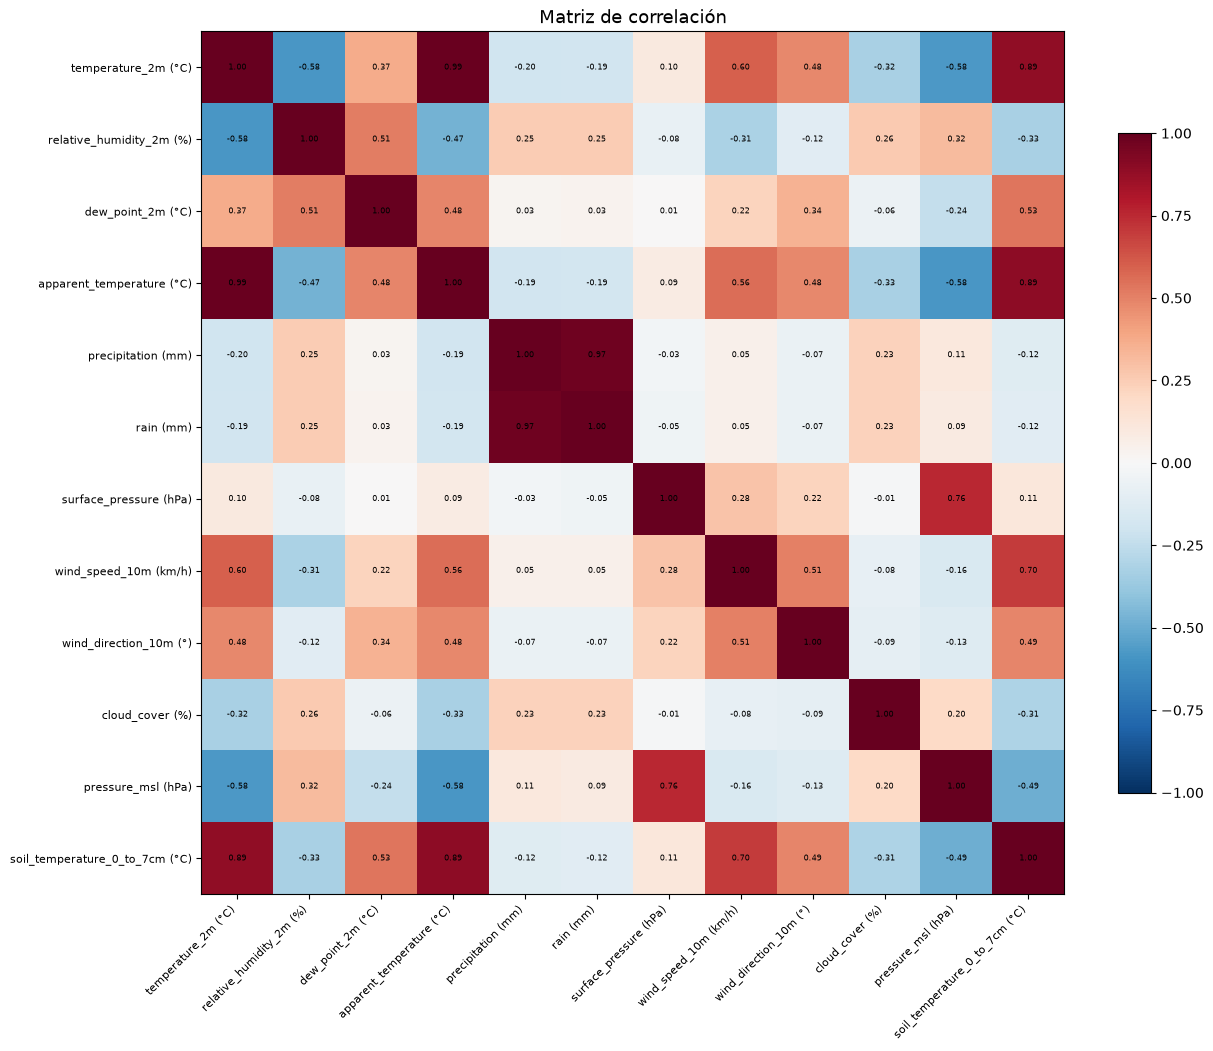

In [10]:
corr = num.corr()

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, shrink=0.7)
plt.title("Matriz de correlación", fontsize=13)
plt.tight_layout()
plt.show()

La matriz revela **redundancias importantes** ($|r| > 0.85$): `temperature_2m` con `apparent_temperature` ($r = 0.99$), `precipitation` con `rain` ($r = 0.97$) y `temperature_2m` con `soil_temperature` ($r = 0.89$). Además `surface_pressure` y `pressure_msl` presentan $r = 0.76$ (misma magnitud física con distinta referencia). Estas variables casi duplicadas aportan poca información nueva y conviene descartarlas en el preprocesamiento.

## 3. Preprocesamiento

Antes de reducir la dimensionalidad y agrupar, aplicamos dos pasos de preprocesamiento, ambos justificados por el análisis exploratorio de la sección 2.

1. **Descarte de variables redundantes.** La matriz de correlación mostró pares casi duplicados: `rain` con `precipitation` ($r = 0.97$), `apparent_temperature` con `temperature_2m` ($r = 0.99$) y `surface_pressure` con `pressure_msl` ($r = 0.76$). Conservamos la variable físicamente más general de cada par y descartamos la otra, para no dar peso doble a la misma información.

2. **Descomposición circular de la dirección del viento.** `wind_direction_10m` es una variable angular en el rango 0–360°, donde 3° y 357° son casi la misma dirección pero numéricamente muy distantes. Como los algoritmos de agrupamiento usan distancia euclidiana, esta discontinuidad crearía artefactos en los datos, por lo que se transforma a la dirección en sus dos componentes $\sin{(\theta)}$ y $\cos{(\theta)}$, que sí varían de forma continua.

In [11]:
# 1) Descarte de variables redundantes (alta correlacion)
df_prep = df.drop(columns=["rain (mm)", "apparent_temperature (°C)", "surface_pressure (hPa)"])

# 2) Descomposicion circular de la direccion del viento
wd_rad = np.deg2rad(df_prep["wind_direction_10m (°)"])
df_prep["wind_dir_sin"] = np.sin(wd_rad)
df_prep["wind_dir_cos"] = np.cos(wd_rad)
df_prep = df_prep.drop(columns=["wind_direction_10m (°)"])

print("Columnas finales:")
print(df_prep.columns.tolist())
print("Dimensiones:", df_prep.shape)

Columnas finales:
['time', 'temperature_2m (°C)', 'relative_humidity_2m (%)', 'dew_point_2m (°C)', 'precipitation (mm)', 'wind_speed_10m (km/h)', 'cloud_cover (%)', 'pressure_msl (hPa)', 'soil_temperature_0_to_7cm (°C)', 'wind_dir_sin', 'wind_dir_cos']
Dimensiones: (17544, 11)


Separamos la matriz de características `X` de la columna `time`, que conservamos aparte para el análisis temporal de la sección 8.

In [12]:
FEATURES = [c for c in df_prep.columns if c != "time"]

X = df_prep[FEATURES].copy()

print("Caracteristicas para clustering:", len(FEATURES))
print("Forma de X:", X.shape)
X.describe().T[["mean", "std", "min", "max"]].round(3)

Caracteristicas para clustering: 10
Forma de X: (17544, 10)


,mean,std,min,max
temperature_2m (°C),15.603,5.957,-2.1,32.9
relative_humidity_2m (%),54.061,20.512,7.0,100.0
dew_point_2m (°C),5.137,5.361,-26.1,15.8
precipitation (mm),0.070,0.416,0.0,8.7
wind_speed_10m (km/h),4.572,4.071,0.0,27.1
cloud_cover (%),34.383,41.838,0.0,100.0
pressure_msl (hPa),1015.922,3.345,1000.7,1033.9
soil_temperature_0_to_7cm (°C),16.718,8.830,-0.4,40.3
wind_dir_sin,0.019,0.728,-1.0,1.0
wind_dir_cos,-0.517,0.449,-1.0,1.0


Tras el preprocesamiento quedan **10 características** y **17.544 observaciones**, cumpliendo el mínimo del enunciado. La tabla descriptiva confirma que las escalas siguen siendo muy heterogéneas, es decir, compuestas por variables de magnitudes muy distintas, lo que motiva la estandarización.

## 4. Reducción de dimensionalidad (PCA)

Como las variables atmosféricas están fuertemente correlacionadas, aplicamos **Análisis de Componentes Principales (PCA)** para reducir la dimensionalidad espacial, eliminando redundancia y reteniendo la mayor parte de la varianza.

### 4.1 Estandarización previa

PCA es sensible a la escala. Como las variables tienen magnitudes muy distintas, primero las estandarizamos a media 0 y desviación 1, para que todas contribuyan por igual a la distancia.

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Forma de X_scaled:", X_scaled.shape)
print("Media por columna:", X_scaled.mean(axis=0).round(6))
print("Desviacion estandar por columna:", X_scaled.std(axis=0).round(6))

Forma de X_scaled: (17544, 10)
Media por columna: [-0. -0.  0. -0.  0. -0.  0.  0. -0. -0.]
Desviacion estandar por columna: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 4.2 Varianza explicada y regla de Kaiser

Ajustamos PCA sin limitar el número de componentes y observamos la varianza explicada por cada uno.

In [14]:
pca = PCA()
pca.fit(X_scaled)

evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)

print("Varianza explicada por componente:")
for i, (e, c) in enumerate(zip(evr, cum), 1):
    print(f"  PC{i:2d}: {e*100:6.2f}%   acumulado {c*100:6.2f}%")

Varianza explicada por componente:
  PC 1:  38.18%   acumulado  38.18%
  PC 2:  17.44%   acumulado  55.63%
  PC 3:  12.64%   acumulado  68.27%
  PC 4:   9.98%   acumulado  78.25%
  PC 5:   7.60%   acumulado  85.85%
  PC 6:   6.40%   acumulado  92.25%
  PC 7:   4.07%   acumulado  96.32%
  PC 8:   2.71%   acumulado  99.03%
  PC 9:   0.79%   acumulado  99.82%
  PC10:   0.18%   acumulado 100.00%


En datos estandarizados, el autovalor de cada componente es su varianza. La **regla de Kaiser** sugiere retener los componentes con autovalor mayor que 1, es decir, los que aportan más varianza que una variable original.

In [15]:
ev = pca.explained_variance_
print("Autovalores:", ev.round(3).tolist())
print("Componentes con autovalor > 1:", int((ev > 1).sum()))

Autovalores: [3.819, 1.744, 1.264, 0.998, 0.76, 0.64, 0.407, 0.271, 0.079, 0.018]
Componentes con autovalor > 1: 3


### 4.3 Gráfico de codo y varianza acumulada

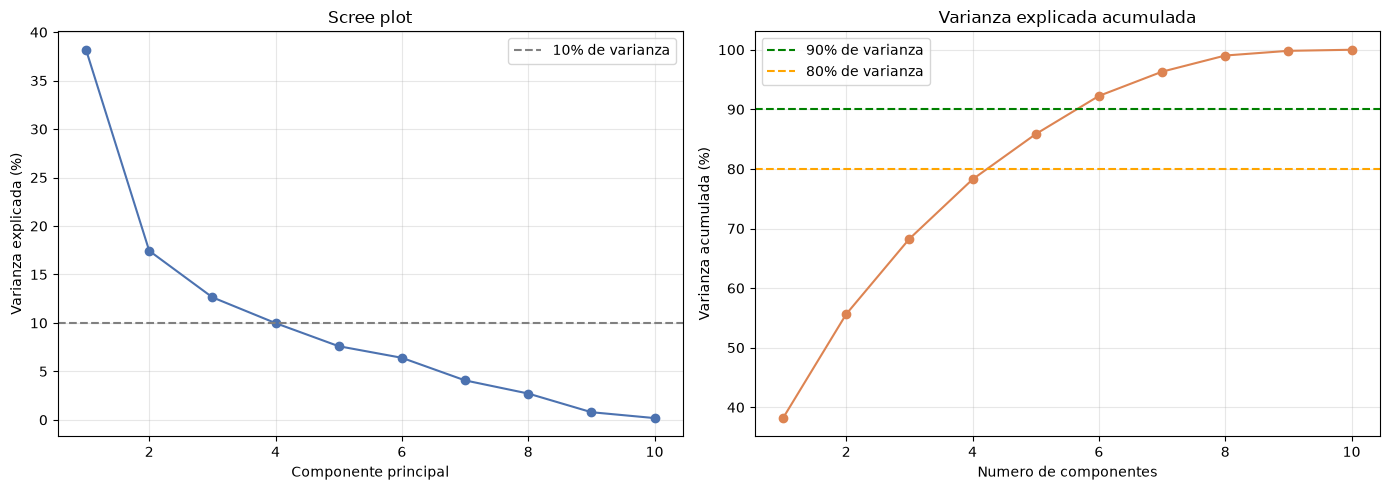

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].plot(range(1, len(evr) + 1), evr * 100, "o-", color="#4C72B0")
axes[0].axhline(y=10, color="gray", linestyle="--", label="10% de varianza")
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Varianza explicada (%)")
axes[0].set_title("Scree plot")
axes[0].legend(); axes[0].grid(alpha=0.3)

# Varianza acumulada
axes[1].plot(range(1, len(cum) + 1), cum * 100, "o-", color="#DD8452")
axes[1].axhline(y=90, color="green", linestyle="--", label="90% de varianza")
axes[1].axhline(y=80, color="orange", linestyle="--", label="80% de varianza")
axes[1].set_xlabel("Numero de componentes")
axes[1].set_ylabel("Varianza acumulada (%)")
axes[1].set_title("Varianza explicada acumulada")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4.4 Justificación del número de componentes

La varianza acumulada muestra que los tres primeros componentes concentran el 68.3% de la varianza (coincide con la regla de Kaiser, que sugiere 3), pero con 6 componentes se alcanza el **92.25%**, superando el umbral habitual del 90%. Retenemos **6 componentes** por dos razones: mantener solo 3 descartaría cerca de un tercio de la información, arriesgando perder matices relevantes para detectar la tormenta; y quedarnos con más de 6 apenas suma varianza (los últimos cuatro componentes aportan menos de 8% en total y corresponden a ruido). El umbral del 90% equilibra retener información y eliminar redundancia, lo que hace el agrupamiento geométricamente más estable.

In [17]:
K = 6
pca = PCA(n_components=K)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada con", K, "componentes:", pca.explained_variance_ratio_.sum().round(4))
print("Forma de X_pca:", X_pca.shape)

Varianza explicada con 6 componentes: 0.9225
Forma de X_pca: (17544, 6)


### 4.5 Interpretación de los componentes (loadings)

Los *loadings* indican el peso de cada variable original en cada componente, lo que permite interpretarlos físicamente.

In [18]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=FEATURES,
    columns=[f"PC{i+1}" for i in range(K)],
)
loadings.round(2)

,PC1,PC2,PC3,PC4,PC5,PC6
temperature_2m (°C),0.48,-0.11,0.07,0.11,0.07,0.02
relative_humidity_2m (%),-0.24,0.59,0.30,-0.18,-0.05,-0.01
dew_point_2m (°C),0.22,0.53,0.45,-0.13,0.05,0.02
precipitation (mm),-0.11,0.32,-0.11,0.74,-0.45,-0.27
wind_speed_10m (km/h),0.38,0.14,-0.36,0.15,-0.15,0.21
cloud_cover (%),-0.19,0.29,-0.29,0.34,0.77,0.23
pressure_msl (hPa),-0.28,0.18,-0.42,-0.31,-0.39,0.43
soil_temperature_0_to_7cm (°C),0.48,0.08,0.10,0.07,-0.04,0.03
wind_dir_sin,-0.37,-0.22,0.20,0.12,0.04,-0.37
wind_dir_cos,-0.16,-0.25,0.50,0.37,-0.12,0.71


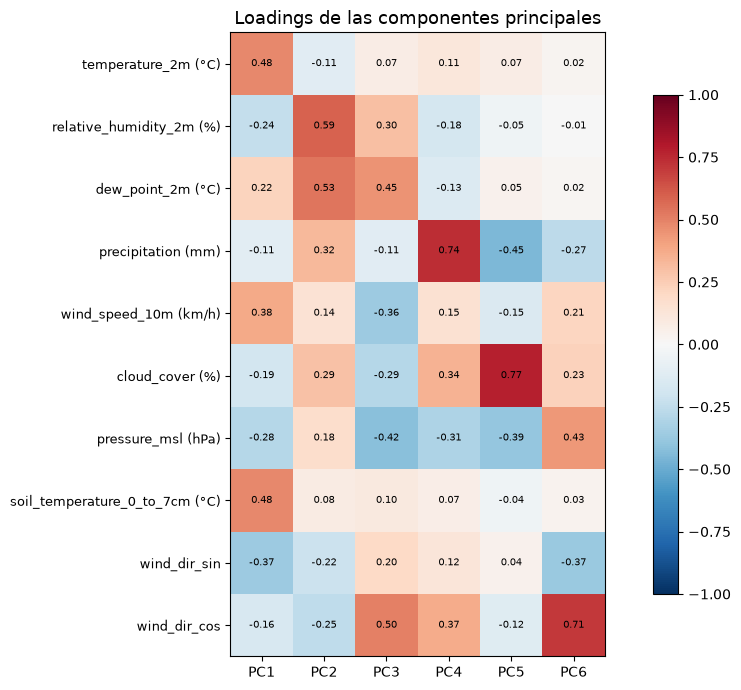

In [19]:
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(loadings.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(K)); ax.set_xticklabels(loadings.columns)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(loadings.index, fontsize=9)
for i in range(len(FEATURES)):
    for j in range(K):
        ax.text(j, i, f"{loadings.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, shrink=0.8)
plt.title("Loadings de las componentes principales", fontsize=13)
plt.tight_layout()
plt.show()

Los componentes principales se interpretan así:

* **Eje térmico - PC1 - 38.2%** Son las cargas positivas altas en `temperature_2m`, `soil_temperature` y `wind_speed`, y negativas en `pressure_msl` y `relative_humidity`. Separa condiciones cálidas y de baja presión de condiciones frías y de alta presión, capturando el ciclo de temperatura (diurno y estacional).

* **Eje de nubosidad - PC2 - 17.4%** Son las cargas positivas en `relative_humidity`, `dew_point`, `precipitation` y `cloud_cover`. Distingue episodios húmedos y nublados de secos y despejados.

* **Eje de viento y presión - PC3 - 12.6%** Son las cargas dominadas por `wind_dir_cos`, `pressure_msl`, `wind_speed` y `dew_point`. Captura la dirección del viento junto con los cambios de presión asociados en los frentes meteorológicos.

Los componentes restantes **PC4 - PC5 - PC6** solo aportan el 10%, 7.6% y 6.4% correspondientemente, recogiendo datos de interacción entre precipitación, nubosidad y presión que también importan de las anomalías.

## 5. Clustering

Aplicamos dos enfoques de agrupamiento sobre el espacio reducido `X_pca` (6 componentes): Primero una partición por centroides utilizando el algoritmo K-Means y luego un agrupamiento por densidad con DBSCAN.

### 5.1 K-Means 
K-Means asigna cada observación al centroide más cercano y minimiza la varianza dentro de cada clúster. Para elegir el número de clústeres $k$ combinamos el **método del codo** (inercia o WCSS) con el **coeficiente de Silhouette**, evaluando $k$ de 2 a 10.

In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Ks = range(2, 11)
inertias, sils = [], []
for k in Ks:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_pca, labels))

for k, i, s in zip(Ks, inertias, sils):
    print(f"k={k:2d}   inercia={i:9.1f}   silhouette={s:.4f}")

k= 2   inercia= 114919.4   silhouette=0.2700
k= 3   inercia=  97033.8   silhouette=0.2516
k= 4   inercia=  83210.1   silhouette=0.2551
k= 5   inercia=  70830.5   silhouette=0.2682
k= 6   inercia=  63207.3   silhouette=0.2380
k= 7   inercia=  58058.8   silhouette=0.2499
k= 8   inercia=  54169.0   silhouette=0.2245
k= 9   inercia=  51085.8   silhouette=0.2334
k=10   inercia=  48378.0   silhouette=0.2341


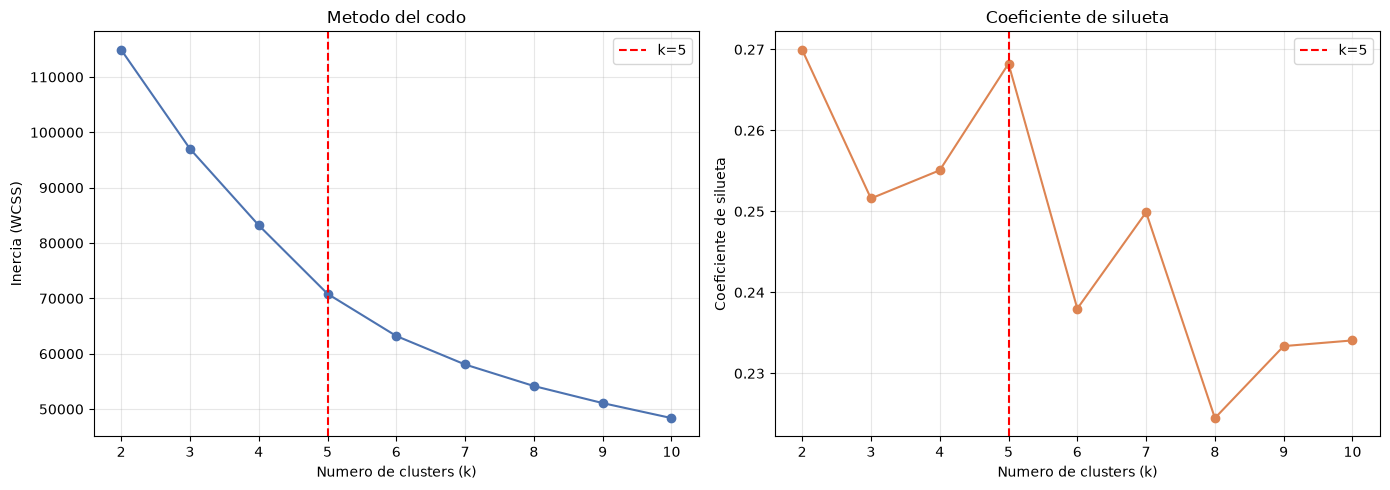

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(Ks), inertias, "o-", color="#4C72B0")
axes[0].set_xlabel("Numero de clusters (k)")
axes[0].set_ylabel("Inercia (WCSS)")
axes[0].set_title("Metodo del codo")
axes[0].axvline(x=5, color="red", linestyle="--", label="k=5")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(list(Ks), sils, "o-", color="#DD8452")
axes[1].set_xlabel("Numero de clusters (k)")
axes[1].set_ylabel("Coeficiente de silueta")
axes[1].set_title("Coeficiente de silueta")
axes[1].axvline(x=5, color="red", linestyle="--", label="k=5")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Elegimos $k = 5$ por dos razones. El codo de la inercia se ubica en 5: el decremento marginal se aplana claramente después de ese punto, y el Silhouette es máximo, excluyendo el caso trivial con $k = 2$, y con $k = 5$ se obtiene 0.268.

In [22]:
km = KMeans(n_clusters=5, random_state=SEMILLA, n_init=10)
labels_km = km.fit_predict(X_pca)

print("Tamano de cada cluster:")
for lbl in range(5):
    n = int((labels_km == lbl).sum())
    print(f"  Cluster {lbl}: {n:5d}  ({n/len(labels_km)*100:5.2f}%)")

Tamano de cada cluster:
  Cluster 0:  5204  (29.66%)
  Cluster 1:  4264  (24.30%)
  Cluster 2:  2967  (16.91%)
  Cluster 3:  4817  (27.46%)
  Cluster 4:   292  ( 1.66%)


Para interpretar el significado físico de cada estado, calculamos la media de las variables originales dentro de cada clúster.

In [23]:
df_prep["cluster_km"] = labels_km

df_prep.groupby("cluster_km")[FEATURES].mean().round(2)

,temperature_2m (°C),relative_humidity_2m (%),dew_point_2m (°C),precipitation (mm),wind_speed_10m (km/h),cloud_cover (%),pressure_msl (hPa),soil_temperature_0_to_7cm (°C),wind_dir_sin,wind_dir_cos
cluster_km,,,,,,,,,,
0,22.53,38.25,6.81,0.00,9.30,16.87,1014.27,26.94,-0.64,-0.70
1,15.45,63.67,8.23,0.01,1.48,10.80,1014.31,16.84,0.29,-0.26
2,10.84,38.71,-3.66,0.00,1.65,35.09,1017.22,6.81,0.76,-0.28
3,11.65,70.08,5.96,0.07,3.92,70.11,1018.22,12.08,0.00,-0.70
4,8.07,87.27,6.01,2.86,5.87,94.26,1017.79,9.88,0.48,-0.36


In [24]:
for lbl in range(5):
    sub = df_prep[df_prep["cluster_km"] == lbl]
    print(f"Cluster {lbl}: precip_media={sub['precipitation (mm)'].mean():.3f} mm | "
          f"%horas con lluvia={(sub['precipitation (mm)'] > 0).mean()*100:.1f}% | "
          f"viento_max={sub['wind_speed_10m (km/h)'].max():.1f} km/h")

Cluster 0: precip_media=0.003 mm | %horas con lluvia=1.1% | viento_max=27.1 km/h
Cluster 1: precip_media=0.006 mm | %horas con lluvia=1.6% | viento_max=16.6 km/h
Cluster 2: precip_media=0.003 mm | %horas con lluvia=1.0% | viento_max=8.1 km/h
Cluster 3: precip_media=0.071 mm | %horas con lluvia=16.0% | viento_max=19.2 km/h
Cluster 4: precip_media=2.858 mm | %horas con lluvia=100.0% | viento_max=24.9 km/h


Los cinco estados descubiertos son:

| Cluster | % | Estado | Características |
|---|---|---|---|
| 0 | 29.7% | Cálido seco/ventoso | T = 22.5°C, HR = 38%, viento 9.3 km/h. |
| 1 | 24.3% | Templado suave | T = 15.5°C, HR = 64%, viento 1.5 km/h. |
| 2 | 16.9% | Frío seco | T = 10.8°C, punto rocío en −3.7°C con nubosidad de 35%. |
| 3 | 27.5% | Frío húmedo/nublado | T = 11.7°C, HR = 70%, lluvia 16% de horas. |
| 4 | **1.7%** | **Tormenta/lluvia intensa** | T = 8°C, HR = 87%, lluvia durante el 100% de horas, precipitación media de 2.86 mm. |

El **cluster 4** es claramente la firma de la tormenta: un estado poco frecuente (1.7% de las horas) caracterizado por humedad extrema, cobertura total de nubes y precipitación continua.

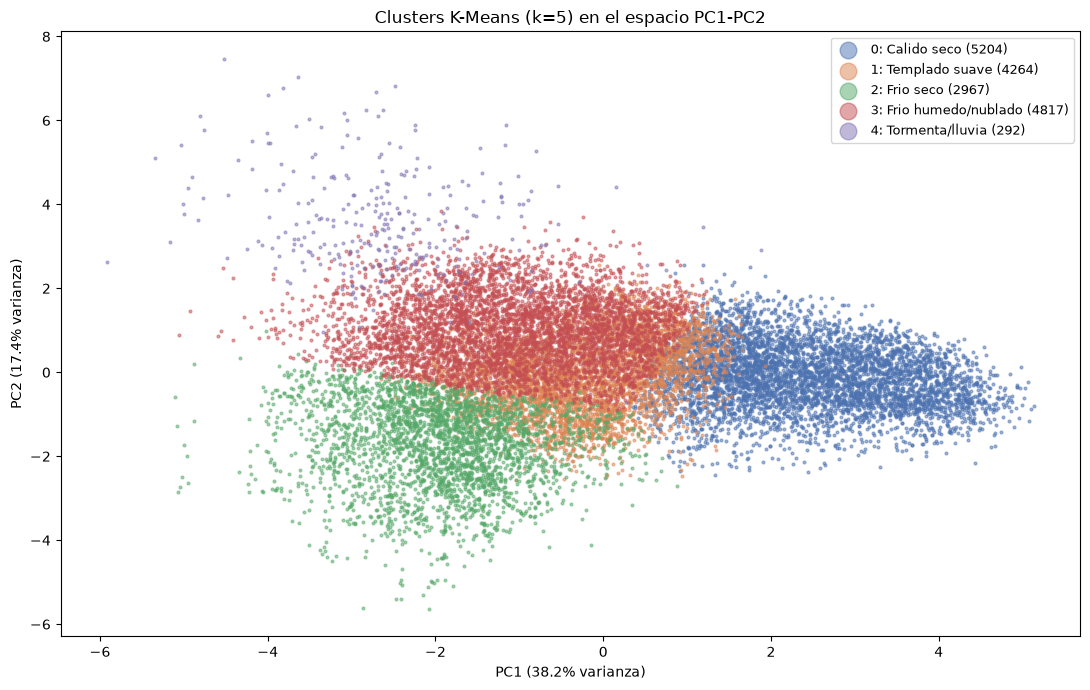

In [25]:
nombres = {0: "Calido seco", 1: "Templado suave", 2: "Frio seco",
           3: "Frio humedo/nublado", 4: "Tormenta/lluvia"}
colores = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2"]

fig, ax = plt.subplots(figsize=(11, 7))
for lbl in range(5):
    m = labels_km == lbl
    ax.scatter(X_pca[m, 0], X_pca[m, 1], s=4, c=colores[lbl],
               label=f"{lbl}: {nombres[lbl]} ({m.sum()})", alpha=0.5)
ax.set_xlabel("PC1 (38.2% varianza)")
ax.set_ylabel("PC2 (17.4% varianza)")
ax.set_title("Clusters K-Means (k=5) en el espacio PC1-PC2")
ax.legend(markerscale=6, loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

### 5.2 DBSCAN 

DBSCAN agrupa los datos en regiones de alta densidad y aísla las zonas dispersas como ruido (etiqueta $-1$), lo que lo hace especialmente útil para detectar anomalías sin *ground truth*. Tiene dos hiperparámetros: `eps` (radio de vecindad) y `min_samples` (mínimo de puntos para formar un núcleo denso).

In [26]:
from sklearn.neighbors import NearestNeighbors

min_samples = 12  # 2 * numero de dimensiones (6 componentes PCA)

nn = NearestNeighbors(n_neighbors=min_samples)
nn.fit(X_pca)
distancias, _ = nn.kneighbors(X_pca)
kdist = np.sort(distancias[:, -1])

print("Percentiles de la k-distancia:")
for p in [50, 80, 90, 95, 98, 99]:
    print(f"  percentil {p}%: {np.percentile(kdist, p):.4f}")

Percentiles de la k-distancia:
  percentil 50%: 0.5302
  percentil 80%: 0.7366
  percentil 90%: 0.8996
  percentil 95%: 1.1047
  percentil 98%: 1.4650
  percentil 99%: 1.8183


Para elegir `eps` graficamos la distancia al vecino más cercano número 12, ordenada de menor a mayor (gráfico k-distance). El codo de esta curva indica el umbral de densidad.

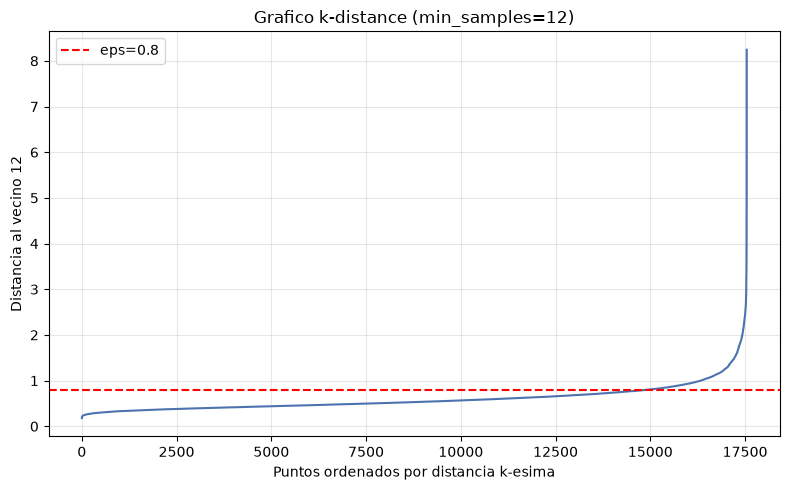

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.arange(1, len(kdist) + 1), kdist, color="#4C72B0")
ax.axhline(y=0.8, color="red", linestyle="--", label="eps=0.8")
ax.set_xlabel("Puntos ordenados por distancia k-esima")
ax.set_ylabel("Distancia al vecino 12")
ax.set_title("Grafico k-distance (min_samples=12)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

El codo se sitúa alrededor de `eps = 0.8`, por lo que elegimos `eps = 0.8` y `min_samples = 12`.

In [28]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.8, min_samples=12)
labels_db = db.fit_predict(X_pca)

import collections
print("Distribucion de etiquetas (label -1 = ruido/anomalia):")
for lbl, cnt in sorted(collections.Counter(labels_db).items()):
    print(f"  etiqueta {lbl}: {cnt}")

Distribucion de etiquetas (label -1 = ruido/anomalia):
  etiqueta -1: 1269
  etiqueta 0: 16243
  etiqueta 1: 18
  etiqueta 2: 14


Caracterizamos físicamente cada grupo igual que con K-Means.

In [29]:
df_prep["cluster_db"] = labels_db

for lbl in sorted(np.unique(labels_db)):
    sub = df_prep[df_prep["cluster_db"] == lbl]
    if len(sub) == 0:
        continue
    print(f"Grupo {lbl} (n={len(sub)}): "
          f"T={sub['temperature_2m (°C)'].mean():.1f} | "
          f"HR={sub['relative_humidity_2m (%)'].mean():.0f} | "
          f"precip={sub['precipitation (mm)'].mean():.2f} | "
          f"%lluvia={(sub['precipitation (mm)'] > 0).mean()*100:.0f} | "
          f"viento={sub['wind_speed_10m (km/h)'].mean():.1f} | "
          f"nubosidad={sub['cloud_cover (%)'].mean():.0f}")

Grupo -1 (n=1269): T=10.6 | HR=67 | precip=0.85 | %lluvia=54 | viento=4.4 | nubosidad=72
Grupo 0 (n=16243): T=16.0 | HR=53 | precip=0.01 | %lluvia=3 | viento=4.6 | nubosidad=31
Grupo 1 (n=18): T=8.7 | HR=85 | precip=0.98 | %lluvia=100 | viento=4.1 | nubosidad=99
Grupo 2 (n=14): T=9.3 | HR=86 | precip=1.69 | %lluvia=100 | viento=4.0 | nubosidad=99


Los grupos se interpretan de la siguiente forma:

* **Cluster 0 (92.6%):** Es el estado dominante con clima seco y templado (T = 16°C, HR = 53%, solo 3% de horas con lluvia). DBSCAN lo identifica como la gran *manifold* de clima normal.

* **Ruido / label −1 (7.2%):** Son las observaciones dispersas que no alcanzan la densidad mínima, con un clima húmedo y nublado con precipitación (54% de horas con lluvia, precipitación media 0.85 mm).

* **Micro-clústeres 1 y 2 (n = 18 y n = 14):** Son los núcleos más extremos, el 100% de horas con lluvia, con humedad entre el 85–86%, la nubosidad 99% y la temperatura 9°C. Son la firma más intensa de la tormenta, tan densa que DBSCAN los aísla como clústeres propios y no como ruido.

Verificamos el solapamiento entre el clúster de tormenta de K-Means y las anomalías de DBSCAN.

In [30]:
tormenta_km = df_prep["cluster_km"] == 4
ruido_db = df_prep["cluster_db"] == -1

print(f"Cluster de tormenta K-Means: {int(tormenta_km.sum())} horas")
print(f"De ellas, capturadas como ruido/anomalia por DBSCAN: "
      f"{int((tormenta_km & ruido_db).sum())} "
      f"({(tormenta_km & ruido_db).sum() / tormenta_km.sum() * 100:.1f}%)")

Cluster de tormenta K-Means: 292 horas
De ellas, capturadas como ruido/anomalia por DBSCAN: 278 (95.2%)


El **95.2%** de las horas de tormenta detectadas por K-Means son identificadas por DBSCAN como ruido o anomalía. Dos algoritmos de naturaleza matemática distinta convergen en señalar el mismo subconjunto extremo como la firma de la tormenta.

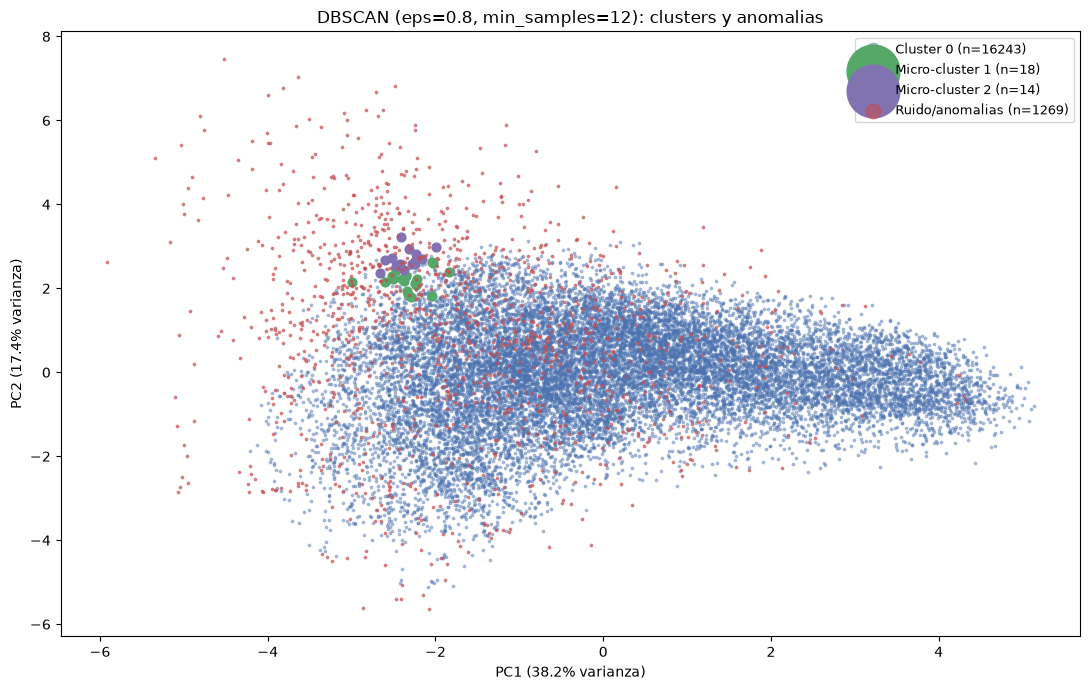

In [31]:
fig, ax = plt.subplots(figsize=(11, 7))
m0 = labels_db == 0
ax.scatter(X_pca[m0, 0], X_pca[m0, 1], s=3, c="#4C72B0", alpha=0.4, label=f"Cluster 0 (n={m0.sum()})")
m1 = labels_db == 1
ax.scatter(X_pca[m1, 0], X_pca[m1, 1], s=40, c="#55A868", label=f"Micro-cluster 1 (n={m1.sum()})")
m2 = labels_db == 2
ax.scatter(X_pca[m2, 0], X_pca[m2, 1], s=40, c="#8172B2", label=f"Micro-cluster 2 (n={m2.sum()})")
mn = labels_db == -1
ax.scatter(X_pca[mn, 0], X_pca[mn, 1], s=3, c="#C44E52", alpha=0.6, label=f"Ruido/anomalias (n={mn.sum()})")
ax.set_xlabel("PC1 (38.2% varianza)"); ax.set_ylabel("PC2 (17.4% varianza)")
ax.set_title("DBSCAN (eps=0.8, min_samples=12): clusters y anomalias")
ax.legend(markerscale=6, loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

## 6. Validación interna de los agrupamientos

Como no existe *ground truth*, evaluamos la calidad de los clústeres con **métricas de validación interna**, que miden propiedades geométricas de la partición usando solo los propios datos. Usamos tres métricas complementarias.

**1. Coeficiente de Silhouette.** Para cada punto $i$, la distancia media a los puntos $a_i$ de su propio clúster y la distancia media al clúster vecino más cercano $b_i$. Se define el valor del punto como:

$$s_i = \frac{b_i - a_i}{\max(a_i, b_i)},$$

Y el índice global es el promedio sobre todos los puntos, $s = \frac{1}{n}\sum_i s_i$, con $s \in [-1, 1]$. Los valores cercanos a **+1** indican clústeres compactos y bien separados, los cercanos a 0 indican solapamiento entre clústeres, y los negativos representan asignaciones probablemente erróneas.

**2. Índice de Davies-Bouldin.** Para cada clúster $i$ se calcula su dispersión interna $s_i$ (distancia media al centroide) y se compara con la distancia $d_{ij}$ entre centroides:

$$DB = \frac{1}{k}\sum_{i=1}^{k} \max_{j \neq i} \left( \frac{s_i + s_j}{d_{ij}} \right).$$

A diferencia de las otras dos, aquí **valores menores indican mejor partición**: clústeres compactos (dispersión interna $s_i$ pequeña) y bien separados entre sí (distancia $d_{ij}$ grande entre sus centroides).

**3. Índice de Calinski-Harabasz.** Es el cociente entre la dispersión entre clústeres y la dispersión dentro de clústeres, normalizado por grados de libertad:

$$CH = \frac{\mathrm{tr}(B)/(k-1)}{\mathrm{tr}(W)/(n-k)},$$

Donde $B$ es la matriz de dispersión entre clústeres y $W$ la de dispersión dentro de clústeres. Si los valores son muy altos, indican clústeres más densos y mejor separados.

Para DBSCAN, las observaciones etiquetadas como ruido ($-1$) no pertenecen a ningún clúster, por lo que las métricas geométricas se calculan sobre el subconjunto con etiqueta válida, y se reporta además el porcentaje de ruido como indicador adicional propio del enfoque por densidad.

In [32]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

def metricas_internas(X, labels, nombre):
    mask = labels != -1
    Xv, lv = X[mask], labels[mask]
    sil = silhouette_score(Xv, lv)
    db = davies_bouldin_score(Xv, lv)
    ch = calinski_harabasz_score(Xv, lv)
    ruido = int((~mask).sum())
    print(f"{nombre:8s} | silhouette={sil:.4f} | davies_bouldin={db:.4f} | "
          f"calinski_harabasz={ch:.1f} | ruido={ruido} ({ruido/len(labels)*100:.2f}%)")
    return sil, db, ch, ruido

res_km = metricas_internas(X_pca, labels_km, "K-Means")
res_db = metricas_internas(X_pca, labels_db, "DBSCAN")

K-Means  | silhouette=0.2682 | davies_bouldin=1.2858 | calinski_harabasz=5633.9 | ruido=0 (0.00%)
DBSCAN   | silhouette=0.1634 | davies_bouldin=0.8400 | calinski_harabasz=38.7 | ruido=1269 (7.23%)


In [33]:
tabla = pd.DataFrame(
    {
        "Silhouette (mayor mejor)": [res_km[0], res_db[0]],
        "Davies-Bouldin (menor mejor)": [res_km[1], res_db[1]],
        "Calinski-Harabasz (mayor mejor)": [res_km[2], res_db[2]],
        "Ruido/anomalias": [f"{res_km[3]} (0.00%)",
                           f"{res_db[3]} ({res_db[3]/len(labels_db)*100:.2f}%)"],
    },
    index=["K-Means (k=5)", "DBSCAN (eps=0.8, m=12)"],
)
tabla.round(4)

,Silhouette (mayor mejor),Davies-Bouldin (menor mejor),Calinski-Harabasz (mayor mejor),Ruido/anomalias
K-Means (k=5),0.2682,1.2858,5633.8787,0 (0.00%)
"DBSCAN (eps=0.8, m=12)",0.1634,0.8400,38.7069,1269 (7.23%)


### Interpretación de los resultados

| Métrica | K-Means (k=5) | DBSCAN | Ganador |
|---|---|---|---|
| Silhouette (mayor mejor) | **0.268** | 0.163 | K-Means |
| Davies-Bouldin (menor mejor) | 1.286 | **0.840** | DBSCAN |
| Calinski-Harabasz (mayor mejor) | **5634** | 39 | K-Means |
| Ruido aislado | 0% | **7.23%** | DBSCAN |

Las métricas no son directamente comparables entre ambos algoritmos porque optimizan objetivos distintos. **K-Means** obtiene mejor Silhouette y Calinski-Harabasz porque su objetivo es, precisamente, construir clústeres compactos y convexos minimizando la varianza interna: al forzar $k = 5$ grupos balanceados, la compacidad geométrica es alta, pero no aísla anomalías (cada punto, por raro que sea, se asigna al centroide más cercano). **DBSCAN** obtiene mejor Davies-Bouldin porque sus clústeres densos están bien separados, pero su Silhouette es menor porque su clúster dominante es una *manifold* alargada (no esférica), que la métrica penaliza. Su valor real está en la columna de ruido: identifica el 7.23% de las observaciones como dispersas, y esas son justamente las candidatas a anomalías.

La métrica adecuada depende del objetivo. Si se quiere una partición geométricamente compacta, K-Means es mejor; si se quiere **detectar anomalías aislando zonas dispersas** (el objetivo de esta tarea), DBSCAN es superior, y su menor Silhouette es el precio por no forzar cada punto a un clúster.

## 7. Discusión técnica comparativa

### 7.1 Efecto de la normalización y la métrica de distancia

Las variables atmosféricas tienen magnitudes y naturalezas muy distintas. La presión se mide en hPa, la humedad en porcentajes, la precipitación en mm y la temperatura en °C. Esta heterogeneidad de escala tiene consecuencias directas en el agrupamiento, porque tanto K-Means como DBSCAN se basan en una métrica de distancia entre puntos de los datos.

A continuación mostramos de forma empírica cómo cambian los resultados según el método de normalización y la métrica de distancia elegida.

#### Experimento 1: Normalización

In [34]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import davies_bouldin_score

print("K-Means (k=5, euclidiana) bajo distintos escalados:")
print(f"{'Escalado':20s} {'Silhouette':>11s} {'Davies-B':>9s} {'tam. min':>10s}")
for nombre, sc in [("Sin escalar", None), ("StandardScaler", StandardScaler()),
                   ("MinMaxScaler", MinMaxScaler()), ("RobustScaler", RobustScaler())]:
    Xs = X.values if sc is None else sc.fit_transform(X)
    Xp = PCA(n_components=6).fit_transform(Xs)
    km = KMeans(n_clusters=5, random_state=SEMILLA, n_init=10).fit(Xp)
    lbl = km.labels_
    sil = silhouette_score(Xp, lbl)
    db = davies_bouldin_score(Xp, lbl)
    print(f"{nombre:20s} {sil:11.4f} {db:9.4f} {min(np.bincount(lbl)):10d}")

K-Means (k=5, euclidiana) bajo distintos escalados:
Escalado              Silhouette  Davies-B   tam. min
Sin escalar               0.3850    0.8935       1589
StandardScaler            0.2682    1.2858        292
MinMaxScaler              0.3210    1.1717       2936
RobustScaler              0.2504    1.3198       2301


**Observaciones:** Al no escalar el Silhouette parece mayor con 0.385, pero es engañoso, ya que las variables de mayor rango dominan la distancia y dejan de lado a las de menor rango. El resultado es que el clúster de tormenta no emerge por lo que la señal extrema queda diluida.

Con StandardScaler, todas las variables contribuyen por igual, y el clúster extremo aparece como un grupo compacto y minoritario de 292 horas, que es la firma de la tormenta. Esta es la justificación de haber estandarizado antes del PCA y del agrupamiento.

#### Experimento 2: Efecto de la métrica de distancia en DBSCAN

In [35]:
print("DBSCAN (eps=0.8, min_samples=12) bajo distintas metricas:")
print(f"{'Metrica':12s} {'clusters':>9s} {'ruido':>7s}")
for metrica in ["euclidean", "manhattan", "cosine"]:
    db = DBSCAN(eps=0.8, min_samples=12, metric=metrica).fit(X_pca)
    lbl = db.labels_
    nc = len(set(lbl)) - (1 if -1 in lbl else 0)
    nruido = int((lbl == -1).sum())
    print(f"{metrica:12s} {nc:9d} {nruido:7d}")

DBSCAN (eps=0.8, min_samples=12) bajo distintas metricas:
Metrica       clusters   ruido
euclidean            3    1269
manhattan           41   11033
cosine               1       0


**Observación clave:** El resultado es distinto según la métrica, manteniendo el mismo `eps=0.8`:

| Métrica | Clústeres | Ruido |
|---|---|---|
| Euclidiana | 3 | 1.269 (7.2%) |
| Manhattan | 41 | 11.033 (62.9%) |
| Coseno | 1 | 0 |

Podemos ver que la distancia euclidiana es la mejor opción. Tras el PCA las variables están decorrelacionadas y en unidades homogéneas, por lo que la distancia euclidiana es geométricamente significativa, la distancia Manhattan fragmenta el espacio de 41 clústeres y marca como ruido el 63% de los datos, perdiendo sentido, y la métrica coseno colapsa todo en un solo clúster, lo que elimina por completo la capacidad de detectar anomalías extremas.

#### Discusión de resultados 7.1

* **Normalización:** La estandarización es imprescindible para que las variables de baja magnitud no queden enmascaradas por las de alta magnitud. Determina la forma final de los clústeres y la sensibilidad para aislar la anomalía (el clúster de tormenta solo emerge al estandarizar).

* **Métrica de distancia:** Sobre datos decorrelacionados por PCA, la distancia euclidiana es la opción coherente y la que produce una detección de anomalías interpretable. Alternativas como distancia Manhattan o coseno anulan esa capacidad.

Luego la elección de estandarizar los datos, junto a PCA y la distancia Euclidiana logra ser la combinación que permite que la firma matemática de la tormenta emerja como una región separada y detectable.

### 7.2 Contigüidad temporal de las anomalías y ciclo de vida de la tormenta

Los algoritmos de agrupamiento evaluaron cada registro de forma independiente, sin noción del tiempo, sin embargo, las anomalías detectadas representan realmente eventos meteorológicos extremos, por lo que se podría esperar que ocurrieran de forma contigua en el tiempo, porque una tormenta es un proceso que persiste durante varias horas o días.

A continuación analizamos la distribución cronológica de las anomalías.

#### Marcado de anomalías sobre el eje temporal

Marcamos cada hora como anómala con el número $1$ o normal con el número $0$, tanto para el ruido de DBSCAN como para el clúster de tormenta de K-Means.

In [36]:
df_prep["anom_db"] = (labels_db == -1).astype(int)
df_prep["anom_km"] = (labels_km == 4).astype(int)

print("Horas anomalas DBSCAN:", int(df_prep['anom_db'].sum()))
print("Horas anomalas K-Means:", int(df_prep['anom_km'].sum()))

Horas anomalas DBSCAN: 1269
Horas anomalas K-Means: 292


#### Detección de horas contiguas 

Identificamos tramos de horas anómalas consecutivas. Si las anomalías fueran ruido aleatorio, aparecerían aisladas, pero si son reales, formarán rachas largas de tormentas.

In [37]:
def rachas(serie):
    runs, start = [], None
    for i, v in enumerate(serie):
        if v == 1 and start is None:
            start = i
        elif v == 0 and start is not None:
            runs.append((start, i - start)); start = None
    if start is not None:
        runs.append((start, len(serie) - start))
    return runs

for nombre, col in [("DBSCAN ruido", "anom_db"), ("KMeans cluster 4", "anom_km")]:
    r = sorted(rachas(df_prep[col].values), key=lambda x: -x[1])
    print(f"{nombre}: {int(df_prep[col].sum())} horas anomalas en {len(r)} rachas")
    print("  Rachas mas largas (inicio, duracion):")
    for inicio, largo in r[:5]:
        t = df_prep["time"].iloc[inicio]
        print(f"    {t}  ->  {largo}h ({largo/24:.1f} dias)")
    print()

DBSCAN ruido: 1269 horas anomalas en 533 rachas
  Rachas mas largas (inicio, duracion):
    2026-07-15 20:00:00  ->  65h (2.7 dias)
    2025-08-22 13:00:00  ->  34h (1.4 dias)
    2025-05-26 14:00:00  ->  23h (1.0 dias)
    2025-08-21 16:00:00  ->  19h (0.8 dias)
    2025-10-05 03:00:00  ->  17h (0.7 dias)

KMeans cluster 4: 292 horas anomalas en 103 rachas
  Rachas mas largas (inicio, duracion):
    2026-10-06 19:00:00  ->  18h (0.8 dias)
    2026-07-17 10:00:00  ->  15h (0.6 dias)
    2026-07-16 19:00:00  ->  13h (0.5 dias)
    2025-05-26 23:00:00  ->  10h (0.4 dias)
    2026-10-08 18:00:00  ->  9h (0.4 dias)



Se logra ver que las anomalías no aparecen como eventos al azar. Con DBSCAN se detecta 533 rachas contiguas, la mayor de 65 horas. K-Means detecta 103 rachas, la mayor de 18 horas. Esto indica que las observaciones extremas se agrupan en episodios temporales coherentes, consistente con la dinámica real de las tormentas.

#### Serie temporal completa de anomalías

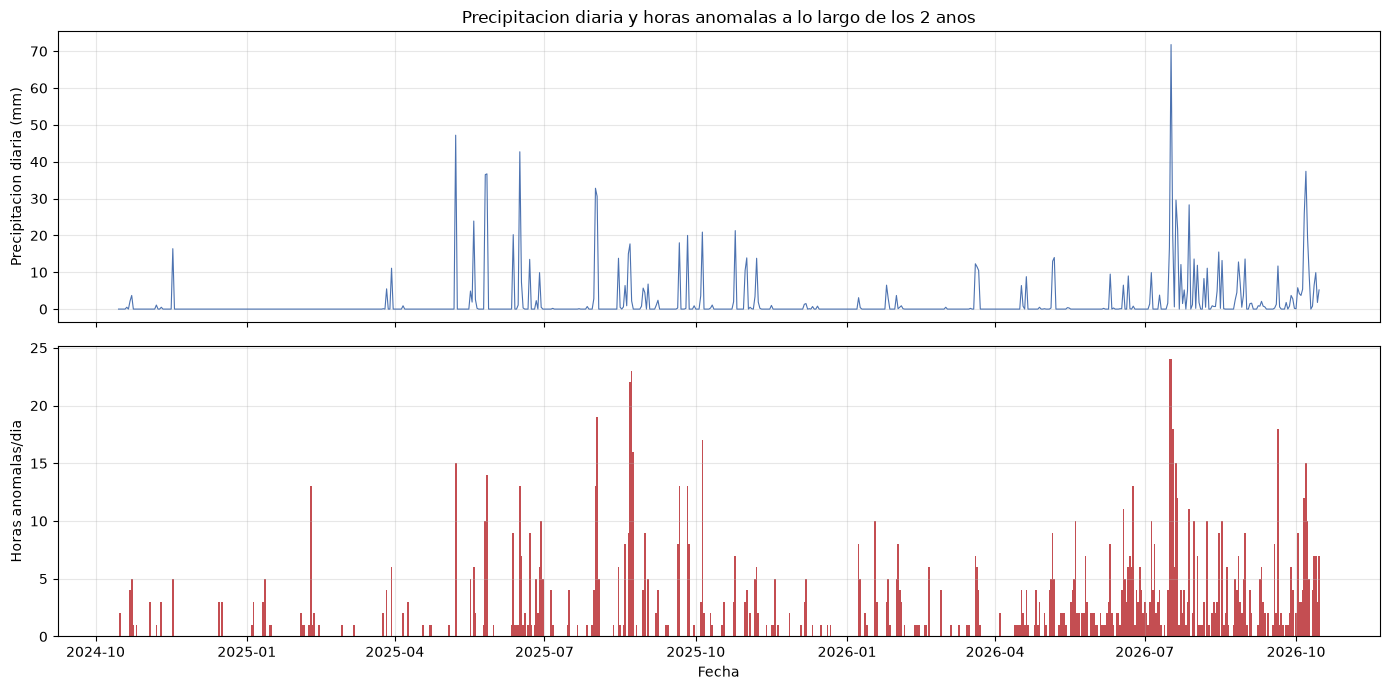

In [38]:
df_prep["fecha"] = df_prep["time"].dt.date
diario = df_prep.groupby("fecha").agg(
    precip=("precipitation (mm)", "sum"),
    n_anom=("anom_db", "sum"),
).reset_index()
diario["fecha"] = pd.to_datetime(diario["fecha"])

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(diario["fecha"], diario["precip"], color="#4C72B0", lw=0.8)
axes[0].set_ylabel("Precipitacion diaria (mm)")
axes[0].set_title("Precipitacion diaria y horas anomalas a lo largo de los 2 anos")
axes[0].grid(alpha=0.3)
axes[1].bar(diario["fecha"], diario["n_anom"], width=1.0, color="#C44E52")
axes[1].set_ylabel("Horas anomalas/dia")
axes[1].set_xlabel("Fecha")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Ciclo de vida de la tormenta principal

Aislamos la racha más larga desde 2026-07-15 hasta 2026-07-18 y analizamos la evolución de presión, precipitación, viento y humedad para evidenciar matemáticamente las tres etapas del ciclo de vida.

In [39]:
t0 = pd.to_datetime("2026-07-15 12:00")
t1 = pd.to_datetime("2026-07-19 12:00")
vent = df_prep[(df_prep["time"] >= t0) & (df_prep["time"] <= t1)].reset_index(drop=True)

p = vent["pressure_msl (hPa)"].values
idx_min = int(np.argmin(p))

print("=== Evidencia matematica del ciclo de vida ===")
print(f"Presion minima (climax): {vent['time'].iloc[idx_min]}  ->  {p[idx_min]:.1f} hPa")
print(f"Fase de FORMACION: caida de presion {p[0]:.1f} -> {p[idx_min]:.1f} = {p[idx_min]-p[0]:.1f} hPa")
print(f"Fase de DISIPACION: subida {p[idx_min]:.1f} -> {p[-1]:.1f} = {p[-1]-p[idx_min]:.1f} hPa")
print(f"Pico de precipitacion: {vent['precipitation (mm)'].max():.2f} mm/h")
print(f"Pico de viento: {vent['wind_speed_10m (km/h)'].max():.1f} km/h")
print(f"Precipitacion acumulada en la ventana: {vent['precipitation (mm)'].sum():.2f} mm")
dp = np.diff(p)
print(f"Maxima caida de presion en 1h: {dp.min():.2f} hPa/h")
print(f"Maxima subida de presion en 1h: {dp.max():.2f} hPa/h")

=== Evidencia matematica del ciclo de vida ===
Presion minima (climax): 2026-07-16 10:00:00  ->  1000.7 hPa
Fase de FORMACION: caida de presion 1011.4 -> 1000.7 = -10.7 hPa
Fase de DISIPACION: subida 1000.7 -> 1011.7 = 11.0 hPa
Pico de precipitacion: 8.70 mm/h
Pico de viento: 16.6 km/h
Precipitacion acumulada en la ventana: 110.50 mm
Maxima caida de presion en 1h: -2.20 hPa/h
Maxima subida de presion en 1h: 2.20 hPa/h


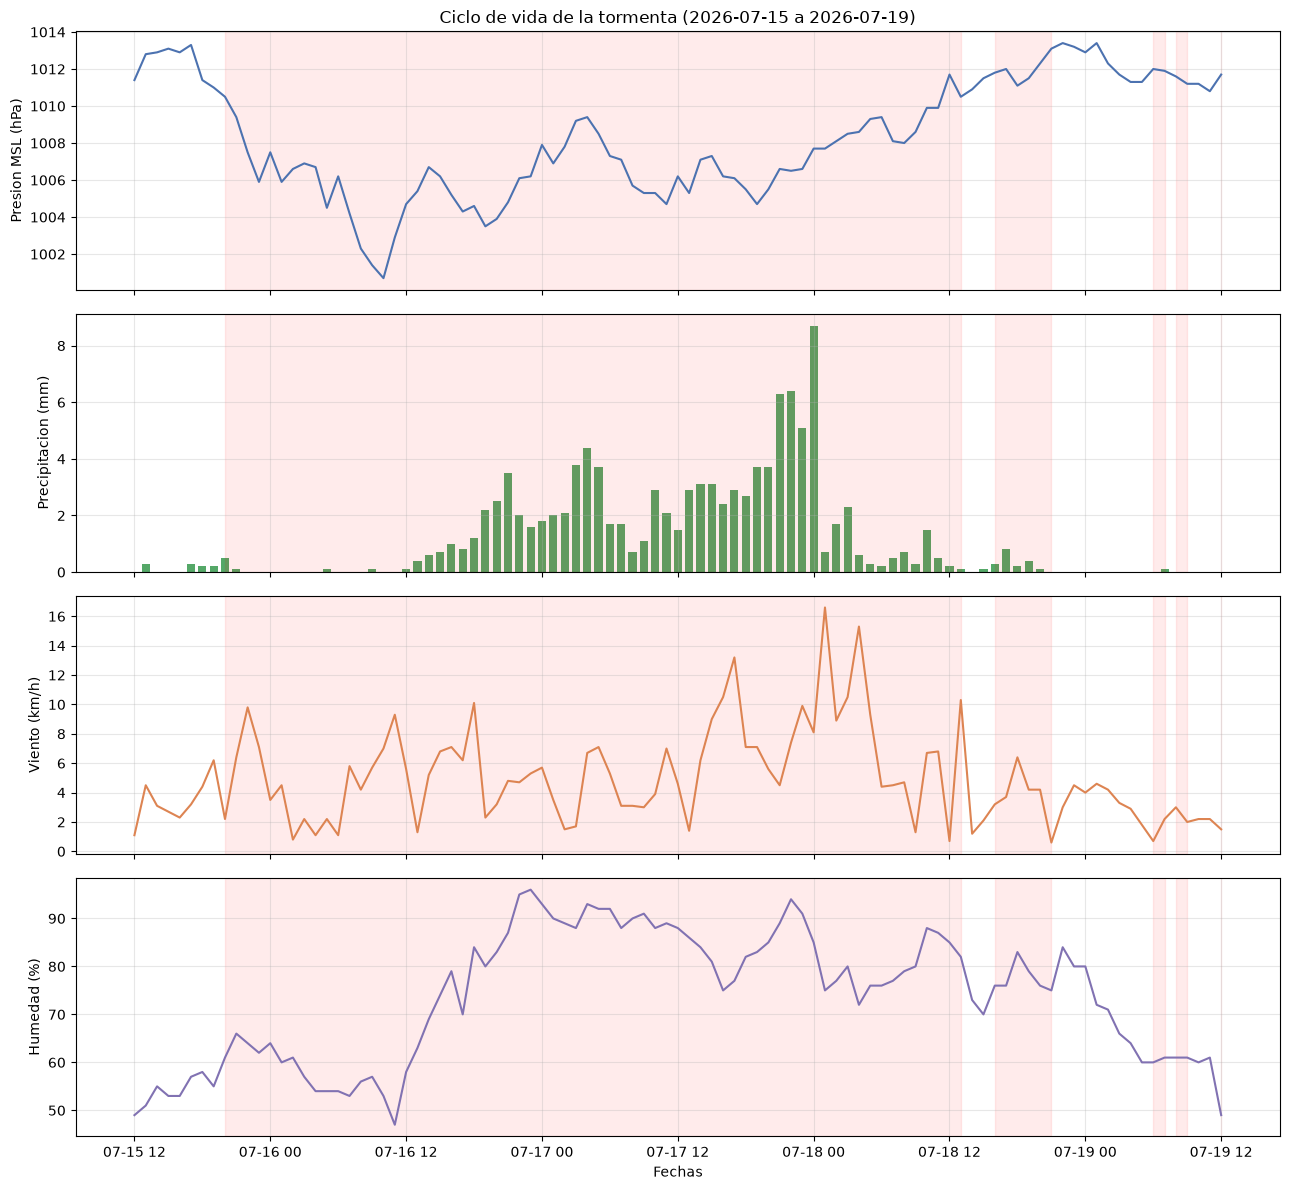

In [40]:
fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True)
t = vent["time"]
axes[0].plot(t, vent["pressure_msl (hPa)"], color="#4C72B0", lw=1.5)
axes[0].set_ylabel("Presion MSL (hPa)"); axes[0].grid(alpha=0.3)
axes[1].bar(t, vent["precipitation (mm)"], width=0.03, color="#55A868")
axes[1].set_ylabel("Precipitacion (mm)"); axes[1].grid(alpha=0.3)
axes[2].plot(t, vent["wind_speed_10m (km/h)"], color="#DD8452", lw=1.5)
axes[2].set_ylabel("Viento (km/h)"); axes[2].grid(alpha=0.3)
axes[3].plot(t, vent["relative_humidity_2m (%)"], color="#8172B2", lw=1.5)
axes[3].set_ylabel("Humedad (%)"); axes[3].set_xlabel("Fechas"); axes[3].grid(alpha=0.3)

anom = vent["anom_db"].values
start = None
for i, v in enumerate(anom):
    if v == 1 and start is None:
        start = i
    elif v == 0 and start is not None:
        for ax in axes:
            ax.axvspan(t.iloc[start], t.iloc[i], color="red", alpha=0.08)
        start = None
if start is not None:
    for ax in axes:
        ax.axvspan(t.iloc[start], t.iloc[-1], color="red", alpha=0.08)

axes[0].set_title("Ciclo de vida de la tormenta (2026-07-15 a 2026-07-19)", fontsize=12)
plt.tight_layout()
plt.show()

A partir de los gráficos, la evidencia confirma las tres etapas del ciclo de vida de una tormenta:

1. **Formación:** Desde 2026-07-15 a las 20:00 hasta 2026-07-16 a las 10:00. La caída sostenida de la presión atmosférica de 10.7 hPa en 22 horas, con un gradiente máximo de −2.2 hPa/h. El descenso de presión es la firma clásica de la aproximación de un sistema de baja presión.

2. **Clímax:** 2026-07-16 a las 10:00. La presión alcanza su mínimo de 1000.7 hPa, coincidiendo con el pico de precipitación de 8.7 mm/h y un viento intenso de velocidad 16.6 km/h. En toda la ventana de una hora se acumulan 110.5 mm de lluvia, un evento extremo para Santiago.

3. **Disipación:** Desde 2026-07-16 a las 10:00 hasta 2026-07-18 a las 00:00. La presión se recupera con +11.0 hPa, la precipitación cesa y las variables vuelven a valores normales.

La zona sombreada en rojo, las anomalías de DBSCAN, coinciden con el período de baja presión y precipitación intensa, validando que el agrupamiento no supervisado recuperó un evento meteorológico real y coherente, pese a no haber usado jamás la información temporal en el modelo.

## 8. Conclusión general

En esta parte abordamos el descubrimiento de la firma matemática de la tormenta eléctrica de Santiago desde un escenario no supervisado, sin *ground truth* ni confirmación visual. Los principales hallazgos son:

1. **Datos y reducción de dimensionalidad:** Trabajamos con un dataset meteorológico de Open-Meteo con 17.544 observaciones horarias y 10 características usadas. Dada la fuerte correlación entre variables atmosféricas, aplicamos **PCA**, reteniendo 6 componentes principales que explican el **92.25%** de la varianza, con una interpretación física clara.

2. **Agrupamiento de datos con K-Means y DBSCAN:** Primero se identificó los 5 estados latentes del clima, aislando un clúster minoritario con un 1.66% de las horas, caracterizado por lluvia en el 100% de las observaciones, humedad extrema y cobertura total con la firma de la tormenta. Luego se detectó el **7.23%** de las observaciones como zonas dispersas (anomalías) y dos micro-clústeres extremos. La validación cruzada mostró que ambos métodos convergen, donde el **95.2%** de las horas de tormenta de K-Means fueron capturadas como anomalías por DBSCAN.

3. **Validación interna:** Definimos y aplicamos Silhouette, Davies-Bouldin y Calinski-Harabasz. Esto para que en K-Means obtuviera una mejor compacidad global, mientras que DBSCAN destacó en su capacidad de aislar dispersión, evidenciando que cada métrica refleja el objetivo geométrico de cada algoritmo.

4. **Rol del preprocesamiento y la distancia:** Demostramos empíricamente que la estandarización es imprescindible, sin ella el clúster de tormenta no logra emerger entre los modelos, y que la distancia Euclidiana sobre datos decorrelacionados por PCA es la única forma de producir una detección de anomalías.

5. **Ciclo de vida de la tormenta:** Aunque los algoritmos ignoraron el tiempo, las anomalías resultaron **contiguas cronológicamente**. La tormenta principal mostró las tres etapas esperadas, la formación, el clímax y la disipación. Esto valida que el enfoque no supervisado recuperó un evento meteorológico real y coherente.

En conjunto, el trabajo demuestra que es posible identificar estados climáticos y eventos extremos sin etiquetas, combinando reducción de dimensionalidad, dos paradigmas de agrupamiento y validación interna, siempre que el preprocesamiento y la métrica de distancia se elijan con criterio físico y estadístico.